# Home Credit Default Risk: End-to-End Pipeline
# 1. Business Understanding
The objective is to predict whether an applicant will have payment difficulties (TARGET = 1). Because defaults are rare (~8% of the dataset), we are dealing with a classic imbalanced classification problem. We will optimize and evaluate our models using ROC-AUC, as standard accuracy would be highly misleading here.

# 2. Deep Dive: The Data and Business Context¶
Before we write any code, it is crucial to understand the data generating process. The data provider, Home Credit, strives to broaden financial inclusion for the unbanked population by providing a positive and safe borrowing experience.

Traditional banks heavily rely on established credit histories. However, many people in Home Credit's target demographic do not have traditional bank accounts or credit scores. To predict repayment ability, Home Credit uses alternative data—including telco and transactional information.

# The Anatomy of application_train.csv
This is our primary table. Every row represents a single loan application, uniquely identified by SK_ID_CURR. The features in this table can be broadly categorized into:

Demographics: Age, gender, family status, number of children.
Socio-Economic Indicators: Income type, education level, occupation type, housing situation.
Loan Specifics: The amount of credit requested, the loan annuity (regular payment amount), and the type of loan (cash vs. revolving).
Behavioral / Alternative Data: How many days before the application did the client change their phone number? When did they update their ID?
External Scores: EXT_SOURCE_1, EXT_SOURCE_2, and EXT_SOURCE_3. These are normalized scores from external data sources (like traditional credit bureaus) and are historically the most powerful predictors in this dataset.

## 2.1 The Relational Database Architecture

This Kaggle competition is not just a single CSV file; it is a full relational database. While we are starting with `application_train.csv` and a simple join with `bureau.csv`, a top-tier model requires extracting features from all available tables.



Here is a breakdown of the surrounding ecosystem:
* **`bureau.csv` & `bureau_balance.csv`**: Information about the client's previous credit lines provided by *other* financial institutions that were reported to the Credit Bureau.
* **`previous_application.csv`**: All previous applications for Home Credit loans of clients who have loans in our sample.
* **`POS_CASH_balance.csv`**: Monthly balance snapshots of previous Point of Sales (POS) and cash loans that the applicant had with Home Credit.
* **`installments_payments.csv`**: Repayment history for previously disbursed credits in Home Credit related to the loans in our sample.
* **`credit_card_balance.csv`**: Monthly balance snapshots of previous credit cards that the applicant has with Home Credit.

**Why does this matter?** As an ML Engineer, handling this architecture requires translating raw transactional logs into cross-sectional features. For example, calculating the *trend* of late payments over the last 6 months from the `installments_payments.csv` table is often more predictive than the applicant's current income.

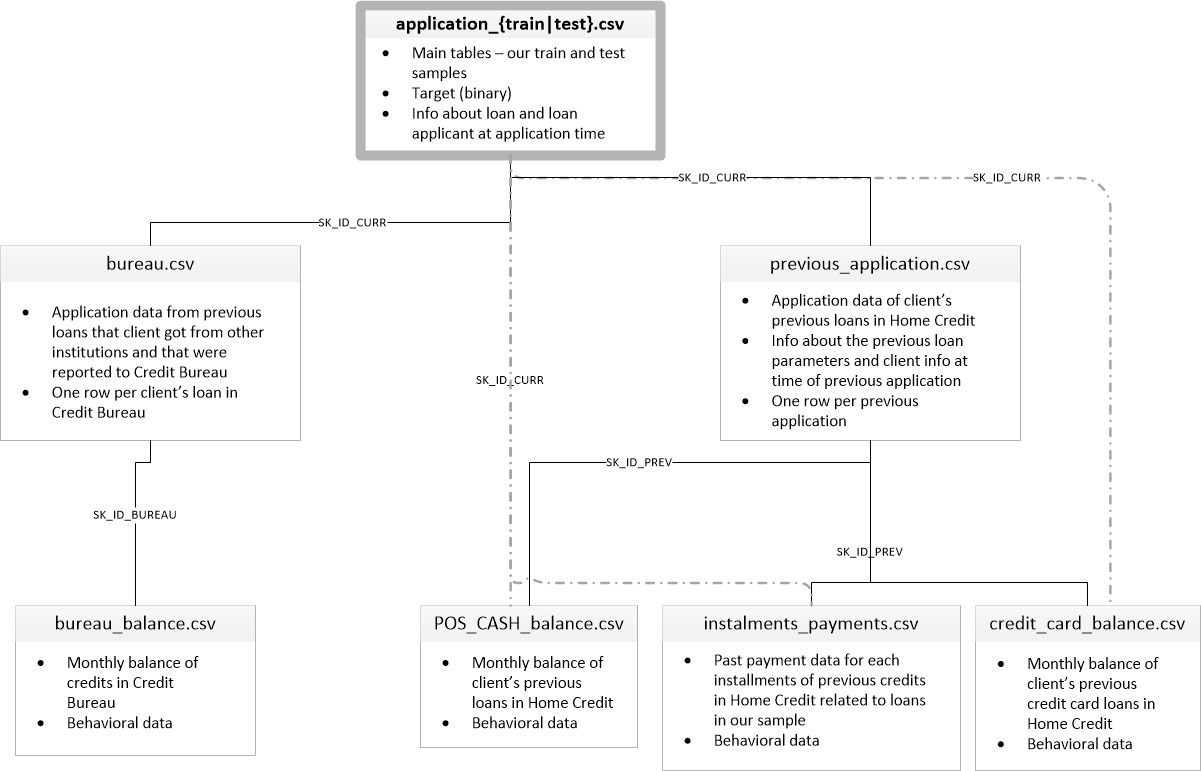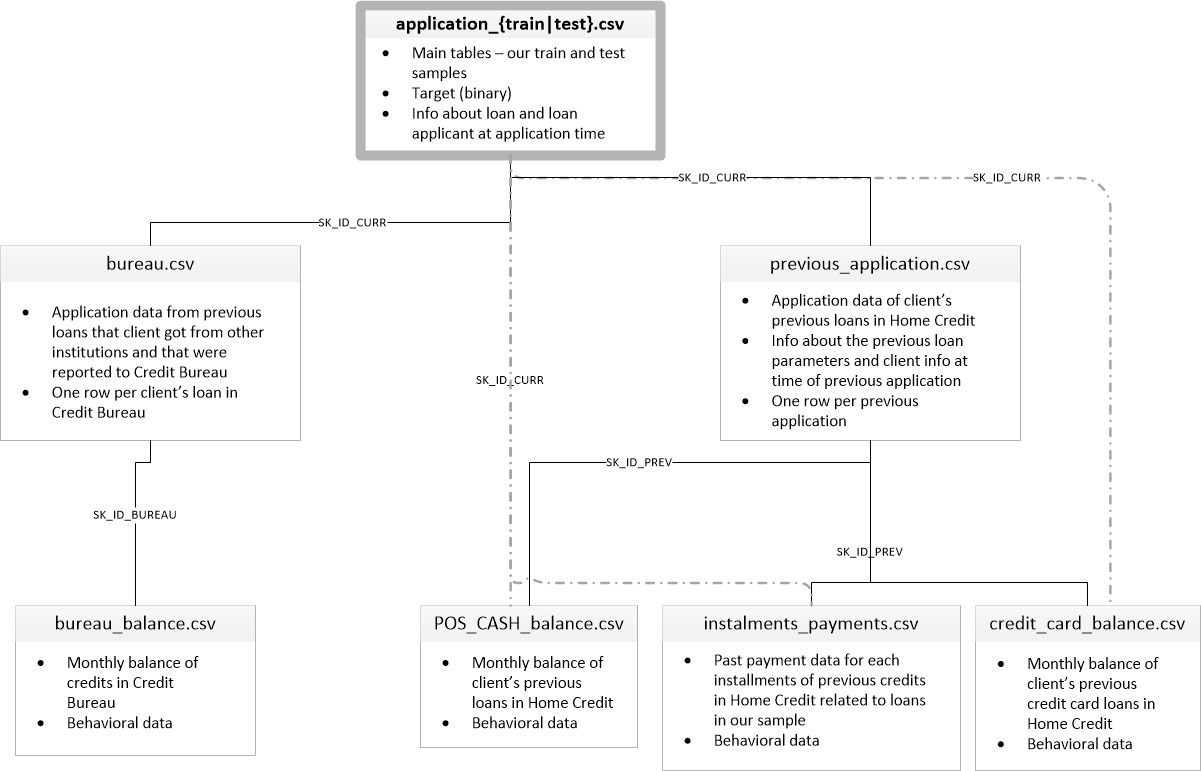

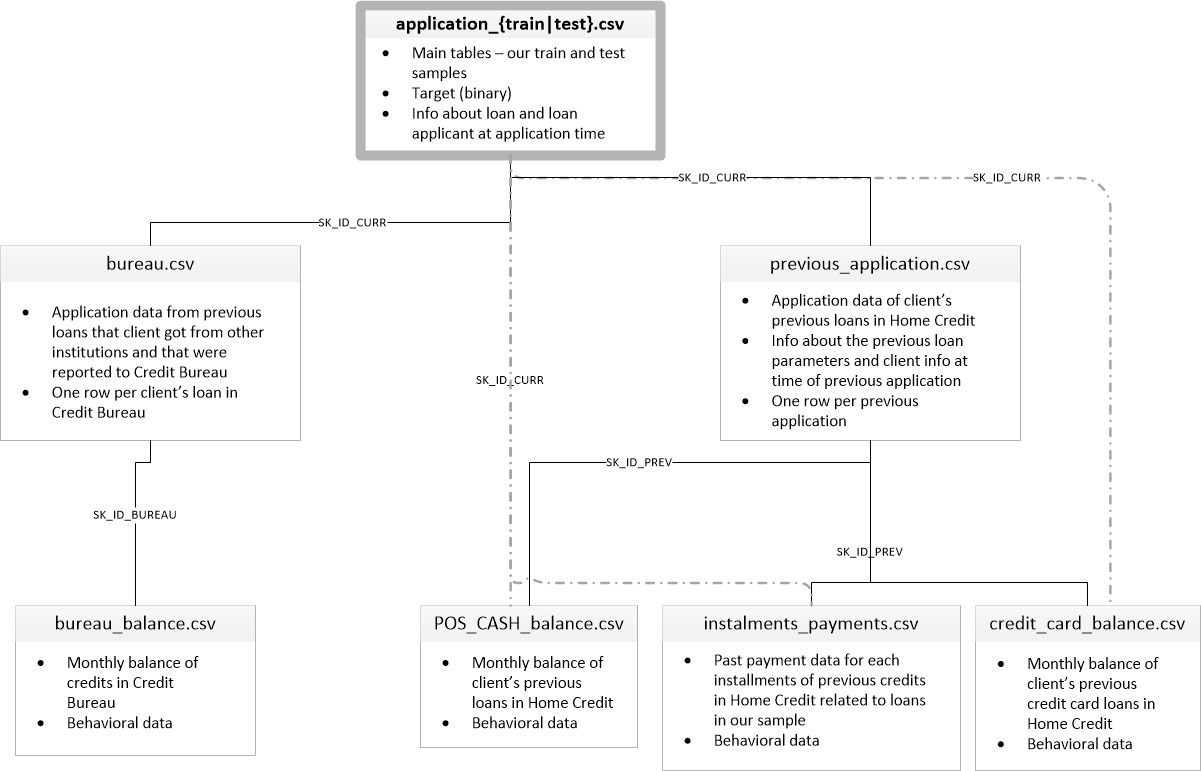
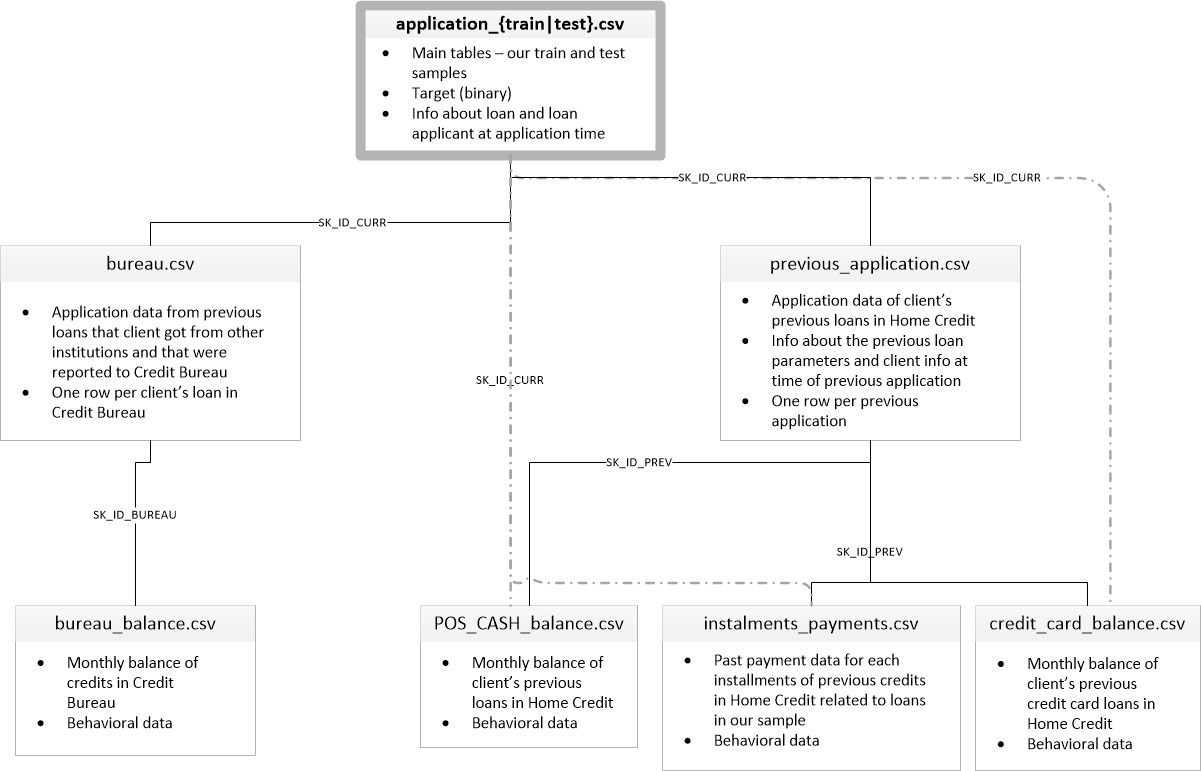
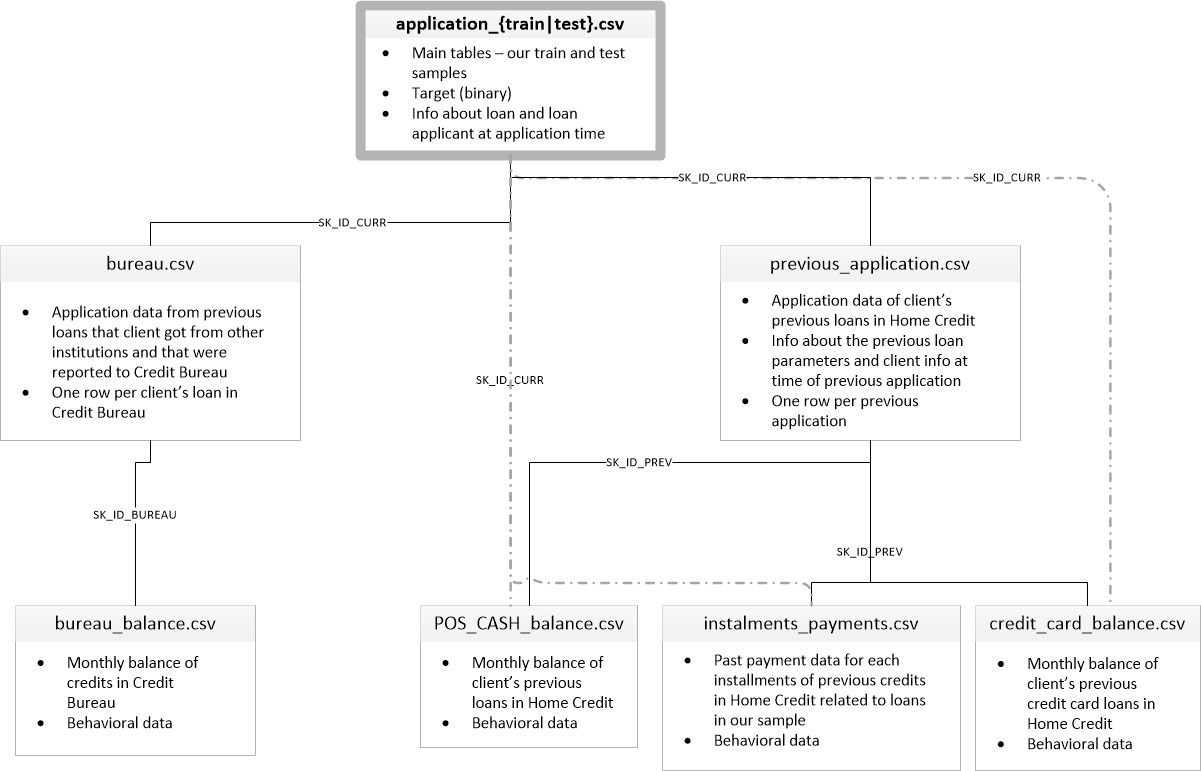
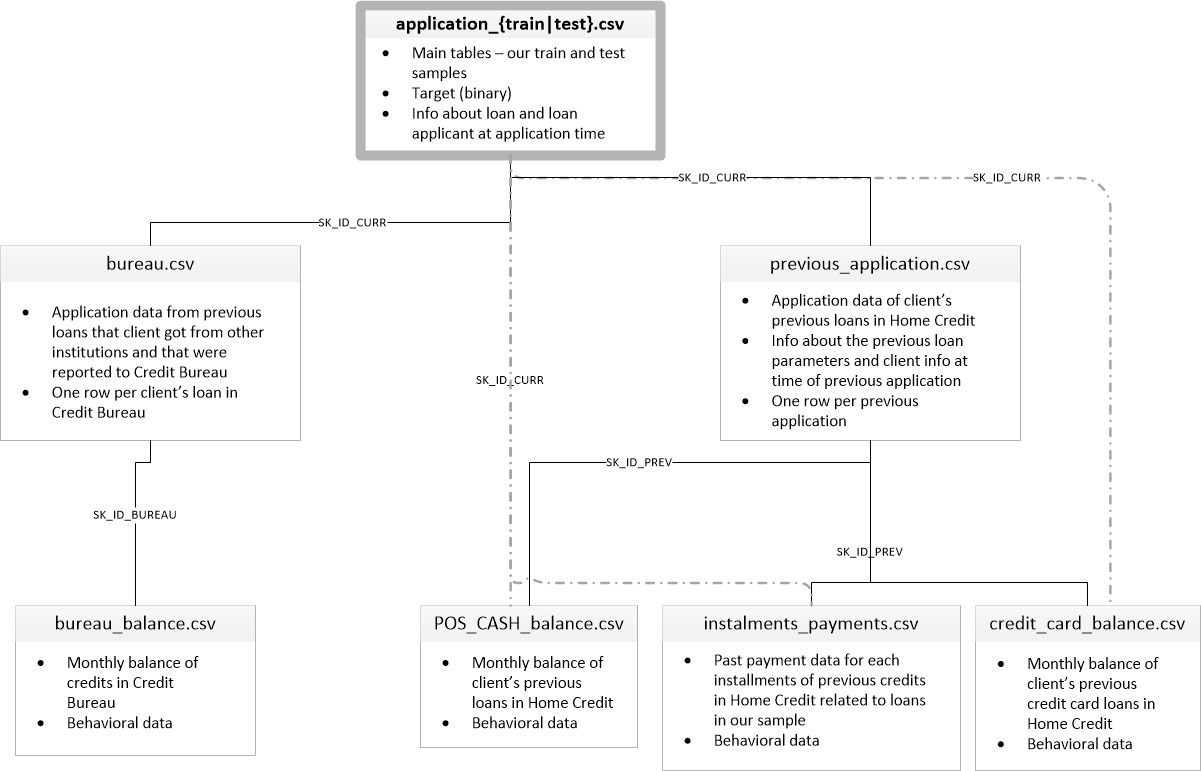

## 2.2 Understanding Missing Data in Finance

When exploring financial risk data, you will encounter massive amounts of missing values (NaNs). It is critical to understand *why* data is missing, as it is rarely random:

1. **Missing Not At Random (MNAR):** If a client has no data in the `credit_card_balance` table, it is likely because they have never owned a credit card. In this case, the *absence* of data is a highly predictive feature in itself. 
2. **Structural Missingness:** Features describing a car's age (`OWN_CAR_AGE`) will be entirely missing for applicants who do not own a car. 
3. **External Limitations:** Missing values in the `EXT_SOURCE` columns might mean the applicant has absolutely no footprint in traditional credit bureaus.

Because of this, dropping rows with missing values is a catastrophic mistake in credit risk modeling. It deletes the exact demographic (the unbanked) that we are trying to score. Instead, we must rely on robust imputation strategies (like filling with the median) or use algorithms like XGBoost/LightGBM which can natively learn branching paths for missing (`NaN`) values.

## 2.3 The Economics of Imbalanced Classification

Our target variable is highly imbalanced: roughly **92%** of loans are repaid (`TARGET = 0`) and **8%** default (`TARGET = 1`). 

From a business perspective, the costs of misclassification are highly asymmetrical:
* **False Positive (Type I Error):** Predicting an applicant will default when they would have repaid. **Cost:** Loss of interest revenue and customer acquisition cost.
* **False Negative (Type II Error):** Predicting an applicant will repay when they actually default. **Cost:** Loss of the entire principal loan amount.

Because a False Negative is exponentially more expensive to a bank than a False Positive, our model cannot treat both errors equally. This is why we rely on the **ROC-AUC** metric, and why we will pass `scale_pos_weight` to our XGBoost model to heavily penalize the algorithm when it misses a default.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import os

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

## 3. Exploratory Data Analysis (EDA)
Before building our pipeline, we need to understand the shape of our data. We will focus on:
* **3.1 Target Variable Distribution:** To visualize the exact class imbalance.
* **3.2 Missing Values Analysis:** To see how much data is absent, which informs our imputation strategy.
* **3.3 Key Numerical Features:** Analyzing distributions of highly predictive features like age and external credit scores.
* **3.4 Correlation Analysis:** Checking how the most important features correlate with the target.

In [4]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Rows and cols of train_df: ")
train_df = pd.read_csv('/kaggle/input/competitions/home-credit-default-risk/application_train.csv')
print(train_df.shape)

Rows and cols of train_df: 
(307511, 122)


### 3.1 Target Variable Distribution
Let's quantify the imbalance. As expected in financial risk, defaults are rare.

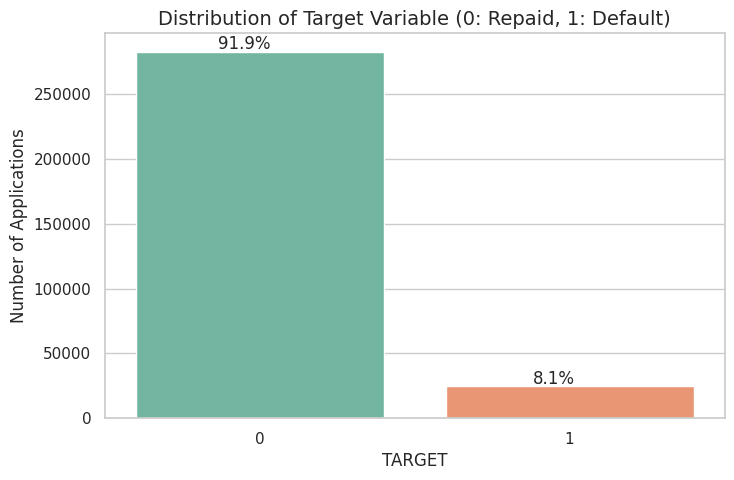

In [5]:
plt.figure(figsize=(8,5))
ax = sns.countplot(data=train_df, x='TARGET', palette='Set2')
plt.title('Distribution of Target Variable (0: Repaid, 1: Default)', fontsize=14)
plt.ylabel('Number of Applications')

# Calculate percentage
total = len(train_df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_height() + 2000
    ax.annotate(percentage, (x, y), ha='center', fontsize=12)

plt.show()

### 3.2 Missing Values Analysis
Financial datasets are notoriously sparse. 
Let's look at the top 15 columns with the highest percentage of missing values. If a column is missing 80%+ of its data, we might eventually consider dropping it rather than imputing.

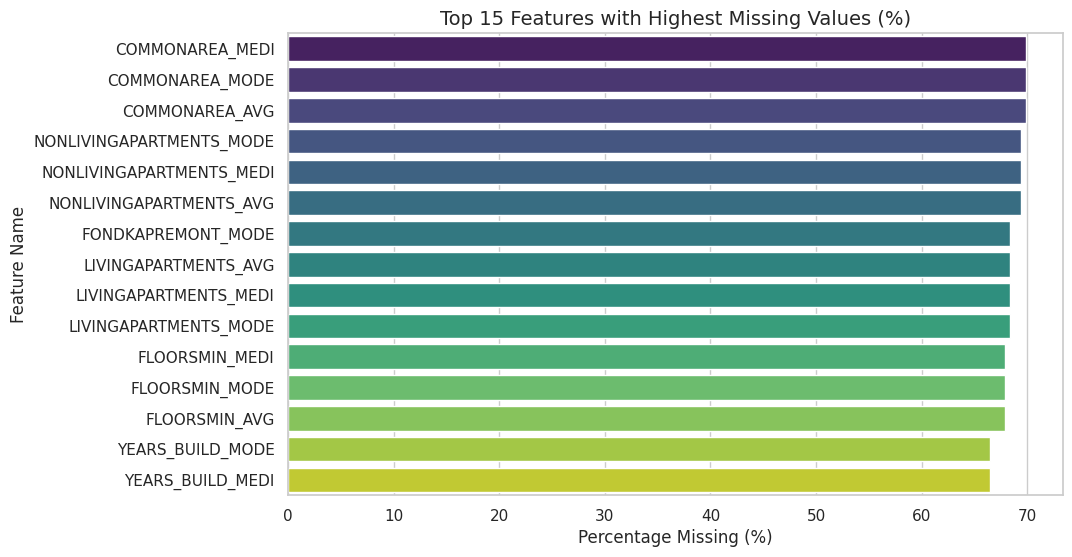

In [6]:
# Calculate percentage of missing values per column
missing_data = train_df.isnull().sum() / len(train_df) * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

# Plot top 15 columns with most missing data
plt.figure(figsize=(10, 6))
sns.barplot(x=missing_data.head(15).values, y=missing_data.head(15).index, palette='viridis')
plt.title('Top 15 Features with Highest Missing Values (%)', fontsize=14)
plt.xlabel('Percentage Missing (%)')
plt.ylabel('Feature Name')
plt.show()

### 3.3 Key Numerical Features (Age & External Sources)
In the Home Credit dataset, `EXT_SOURCE_1`, `EXT_SOURCE_2`, and `EXT_SOURCE_3` are normalized scores from external data sources and are historically the most predictive features. `DAYS_BIRTH` represents the client's age in days (negative values). 

Let's look at their Probability Density Functions (KDE plots) separated by the Target class.

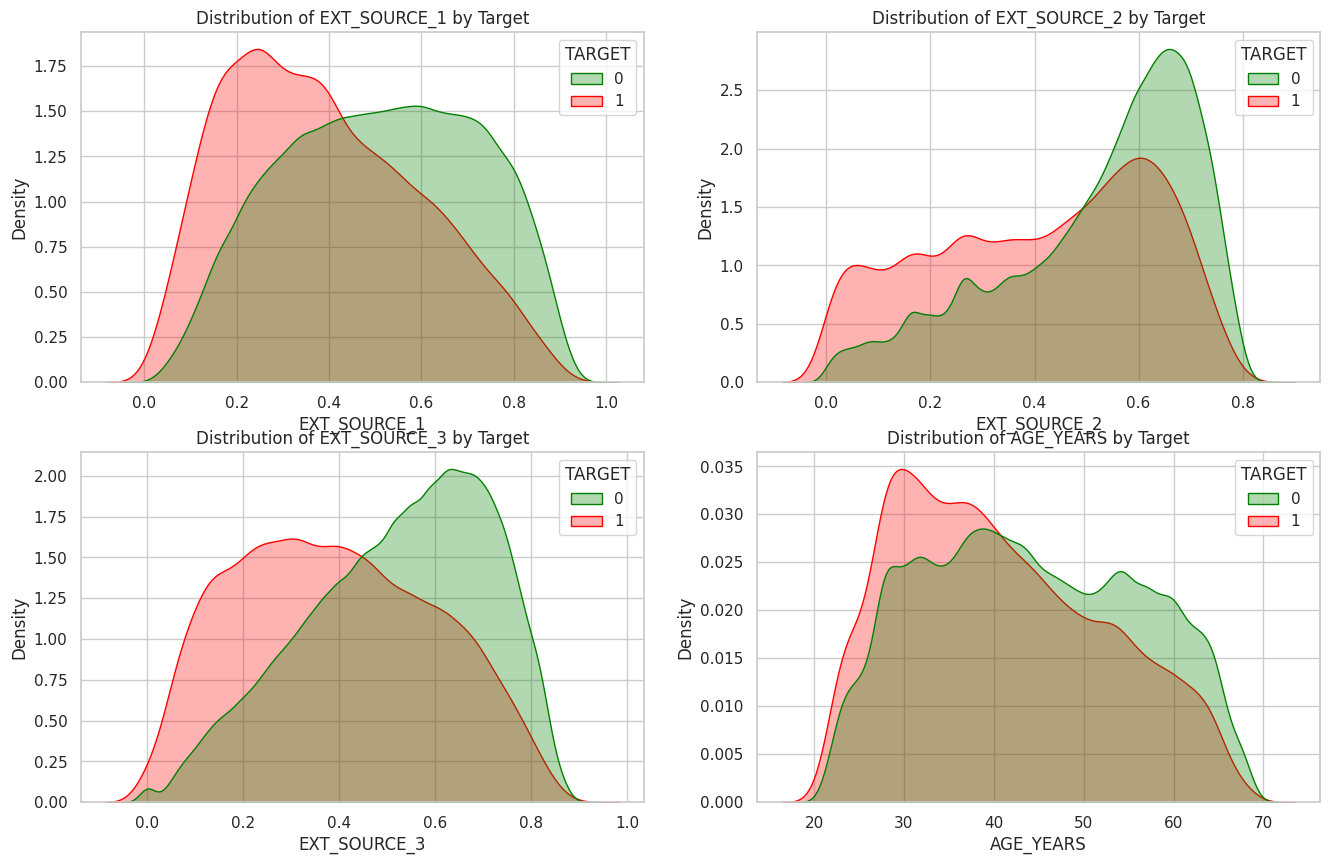

In [7]:
train_df['AGE_YEARS'] = abs(train_df['DAYS_BIRTH']) / 365

features_to_plot = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.kdeplot(data=train_df, x=feature, hue='TARGET', fill=True, common_norm=False, 
                palette=['green', 'red'], alpha=0.3, ax=axes[i])
    axes[i].set_title(f'Distribution of {feature} by Target')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')

plt.show()

### 3.4 Correlation Analysis
Let's see the linear relationships between these top features and our target variable. We should see negative correlations with the `EXT_SOURCE` features (higher score = lower chance of default).

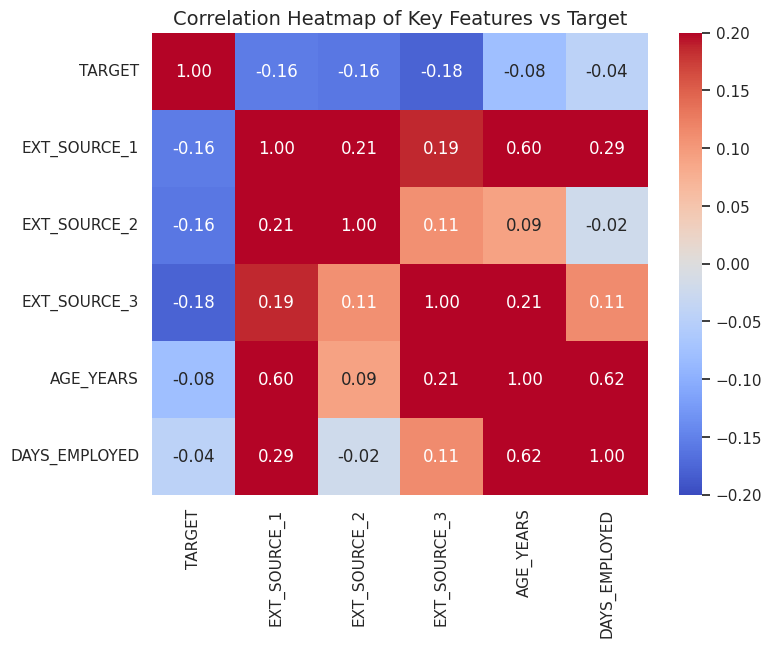

In [8]:
corr_features = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'DAYS_EMPLOYED']
corr_matrix = train_df[corr_features].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-0.2, vmax=0.2)
plt.title('Correlation Heatmap of Key Features vs Target', fontsize=14)
plt.show()

# Drop the temporary AGE_YEARS column so it doesn't interfere with our automated pipeline later
train_df.drop(columns=['AGE_YEARS'], inplace=True)

### 3.5 Feature Engineering & Data Merging
Now that we understand the base data, we will execute the data merge. We load the `bureau.csv` dataset, group by the client ID, extract aggregate statistics (like the mean or max credit they hold elsewhere), and merge it into our training data.

Now we execute the data merge. We load the `bureau.csv` dataset, extract aggregate statistics, and merge it into our training data. 

Additionally, we are engineering three high-impact financial ratios directly inspired by the 1st Place Kaggle Solution. These ratios capture the applicant's financial leverage and purchasing behavior. Link: https://www.kaggle.com/competitions/home-credit-default-risk/writeups/home-aloan-1st-place-solution

In [9]:
# Load bureau df
print("Loading bureau dataset for merging...")
bureau_df = pd.read_csv('/kaggle/input/competitions/home-credit-default-risk/bureau.csv')
bureau_df.shape

# Aggregate Bureau Data once
print("Aggregating bureau data...")
bureau_agg = bureau_df.groupby('SK_ID_CURR').agg({
    'DAYS_CREDIT': ['min', 'max', 'mean'],
    'CREDIT_DAY_OVERDUE': ['max', 'mean'],
    'AMT_CREDIT_SUM': ['max', 'mean', 'sum'],
    'AMT_CREDIT_SUM_DEBT': ['max', 'mean', 'sum']
})

# Flatten the multi-level columns
bureau_agg.columns = pd.Index([f"BUREAU_{e[0]}_{e[1].upper()}" for e in bureau_agg.columns.tolist()])
bureau_agg.reset_index(inplace=True)


# ==========================================
# REUSABLE FEATURE ENGINEERING FUNCTION
# ==========================================
def engineer_features(df, bureau_agg_df):
    """Applies all table merges and mathematical transformations safely."""
    
    # 1. Merge bureau_agg
    df = df.merge(bureau_agg_df, on='SK_ID_CURR', how='left')

    # 2. Add 1st Place Solution Features
    df['CREDIT_ANNUITY_RATIO'] = df['AMT_CREDIT'] / df['AMT_ANNUITY']
    df['CREDIT_GOODS_RATIO'] = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']

    # Safe division for debt ratio to avoid ZeroDivisionError
    df['BUREAU_DEBT_CREDIT_RATIO'] = np.where(df['BUREAU_AMT_CREDIT_SUM_SUM'] > 0, 
        df['BUREAU_AMT_CREDIT_SUM_DEBT_SUM'] / df['BUREAU_AMT_CREDIT_SUM_SUM'], 
        0)
    return df

# Apply function to training data
train_df = engineer_features(train_df, bureau_agg)

print("Final Train shape after EDA and merging:", train_df.shape)

# Separate features and target for the modeling pipeline
x = train_df.drop(columns=['TARGET', 'SK_ID_CURR'])
y = train_df['TARGET']

x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=42)
print("Data successfully split and ready for modeling pipeline.")

Loading bureau dataset for merging...
Aggregating bureau data...
Final Train shape after EDA and merging: (307511, 136)
Data successfully split and ready for modeling pipeline.


## 4. Data Processing Pipeline
Since we already split our data into `x_train`, `x_test`, `y_train`, and `y_test` at the end of our EDA, we can move straight into building our preprocessing engine. 

We will use a `ColumnTransformer` to apply a `median` imputer and `StandardScaler` to numerical features, and a `constant` imputer and `OneHotEncoder` to categorical features.

In [10]:
numeric_features = x_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = x_train.select_dtypes(include=['object']).columns.tolist()

print('Numerical features:', len(numeric_features))
print('Categorical features:', len(categorical_features))

# Preprocessing for numerical cols
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing for categorical cols
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine Preprocessing 
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])
preprocessor

Numerical features: 118
Categorical features: 16


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['CNT_CHILDREN', 'AMT_INCOME_TOTAL',
                                  'AMT_CREDIT', 'AMT_ANNUITY',
                                  'AMT_GOODS_PRICE',
                                  'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH',
                                  'DAYS_EMPLOYED', 'DAYS_REGISTRATION',
                                  'DAYS_ID_PUBLISH', 'OWN_CAR_AGE',
                                  'FLAG_MOBIL', 'FLAG_EMP_PHONE',...
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['NAME_CONTRACT_TYPE', 'CODE_GENDER',
                                  'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
                                  'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE',
                                  'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
                                  'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
                                  'WEEKDAY_APPR_PROCESS_START',
                                  'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE',
                                  'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE',
                                  'EMERGENCYSTATE_MODE'])])

## 5. Model Shortlisting
We initialize 4 algo and test them on a 10% subset of the data. Because our EDA showed severe class imbalance (~92:8), we pass `class_weight='balanced'` or `scale_pos_weight=11` to the models to heavily penalize missing the minority class.

*(Note: SVM is commented out because it scales at $O(n^2)$ to $O(n^3)$ with the number of samples, which would cause the Kaggle notebook to time out even on a subset.)*

In [11]:
models = {
    'RandomForest': RandomForestClassifier(n_estimators=50, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(scale_pos_weight=11, random_state=42, eval_metric='auc', n_jobs=-1), 
    'Neural Network': MLPClassifier(hidden_layer_sizes=(32,), max_iter=100, random_state=42),
    # 'SVM': SVC(probability=True, class_weight='balanced', random_state=42) 
}

# sub sample train-test-split
x_train_sub, _, y_train_sub, _ = train_test_split(x_train, y_train,train_size=0.1, 
                                                  stratify=y_train, random_state=42)

print('Shortlisting Models on 10% subset data')
for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipe.fit(x_train_sub, y_train_sub)

    # Predict
    pred_proba = pipe.predict_proba(x_test)[:,1]
    auc = roc_auc_score(y_test, pred_proba)
    print(f"{name}, Validation score: {auc:.4f}")

Shortlisting Models on 10% subset data
RandomForest, Validation score: 0.6942
XGBoost, Validation score: 0.7055
Neural Network, Validation score: 0.6417


In [12]:
x_train_sub.head(5)

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,BUREAU_CREDIT_DAY_OVERDUE_MEAN,BUREAU_AMT_CREDIT_SUM_MAX,BUREAU_AMT_CREDIT_SUM_MEAN,BUREAU_AMT_CREDIT_SUM_SUM,BUREAU_AMT_CREDIT_SUM_DEBT_MAX,BUREAU_AMT_CREDIT_SUM_DEBT_MEAN,BUREAU_AMT_CREDIT_SUM_DEBT_SUM,CREDIT_ANNUITY_RATIO,CREDIT_GOODS_RATIO,BUREAU_DEBT_CREDIT_RATIO
196727,Cash loans,F,N,Y,0,157500.0,545040.0,25537.5,450000.0,Unaccompanied,...,0.0,305550.0,162859.875,1954318.5,275134.5,102654.09,1231849.08,21.342731,1.2112,0.630322
101244,Cash loans,F,N,Y,0,92250.0,431280.0,22149.0,360000.0,Unaccompanied,...,0.0,274500.0,193252.500,386505.0,263961.0,131980.50,263961.00,19.471759,1.1980,0.682943
173764,Revolving loans,F,N,Y,0,135000.0,405000.0,20250.0,405000.0,Unaccompanied,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000,1.0000,0.000000
213770,Cash loans,M,N,Y,1,72000.0,295668.0,14508.0,193500.0,Unaccompanied,...,0.0,135000.0,135000.000,135000.0,0.0,0.00,0.00,20.379653,1.5280,0.000000
285986,Cash loans,F,N,Y,1,121500.0,274941.0,21406.5,229500.0,Unaccompanied,...,0.0,337500.0,196777.500,590332.5,173533.5,132990.00,398970.00,12.843809,1.1980,0.675839


## 6. Hyperparameter Tuning (GridSearchCV)
Based on typical tabular data results, XGBoost perform best. We will run a cross-validated grid search to tune its hyperparameters on the *full* training set.

In [13]:
print("--- Running GridSearchCV for XGBoost ---")

xgb_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(scale_pos_weight=11, random_state=42, eval_metric='auc'))
])

# Define parameter grid (kept relatively small for notebook execution time)
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5],
    'classifier__learning_rate': [0.05, 0.1]
}

# Used Stratified k fold to maintain 92:8 imbalance in all cross-validation folds
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    xgb_pipe,
    param_grid,
    cv=cv,
    scoring='roc_auc', 
    n_jobs=-1, 
    verbose=1
)


grid_search.fit(x_train, y_train)

best_params = grid_search.best_params_
print('Best parameters: ', best_params)

# Final validation check
best_model = grid_search.best_estimator_
val_pred = best_model.predict_proba(x_test)[:,1]
val_auc = roc_auc_score(y_test, val_pred)
print(f"Final Validation ROC-AUC: {val_auc:.4f}")


--- Running GridSearchCV for XGBoost ---
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:  {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}
Final Validation ROC-AUC: 0.7667


## 7. Model Serialization & Local Inference
We serialize the entire pipeline (imputers, scalers, encoders, and the tuned model) to disk. This ensures all transformation logic is preserved. We then load it back into memory and run predictions on three random validation rows to confirm it works.

In [14]:
# save the model pipeline
model_filename = 'home_credit_xgb_pipeline.joblib'
joblib.dump(best_model, model_filename)
print(f"Model saved successfully to {model_filename}\n")

# Load the saved pipeline
loaded_model = joblib.load(model_filename)


# Take 3 random example from validation set
example_data = x_test.sample(3, random_state=42)
example_true_labels = y_test.loc[example_data.index]

predictions = loaded_model.predict(example_data)
prediction_probabilities = loaded_model.predict_proba(example_data)[:,1]

print('Example Predictions:')
for i, (ind, row) in enumerate(example_data.iterrows()):
    print('Client index: ', ind)
    print('True label: ', example_true_labels.iloc[i], '(1=Default, 0=Repaid)')
    print('Predicted Class: ', predictions[i])
    print(f"Probability of Default: {prediction_probabilities[i]:.2%}\n")

Model saved successfully to home_credit_xgb_pipeline.joblib

Example Predictions:
Client index:  265413
True label:  1 (1=Default, 0=Repaid)
Predicted Class:  1
Probability of Default: 69.99%

Client index:  203790
True label:  0 (1=Default, 0=Repaid)
Predicted Class:  0
Probability of Default: 46.21%

Client index:  300626
True label:  0 (1=Default, 0=Repaid)
Predicted Class:  1
Probability of Default: 57.94%



## 7.1 Feature Importance Analysis

Let's peer inside our XGBoost "black box" to see which features are driving the predictions. We expect the `EXT_SOURCE` variables to dominate, but let's see if our newly engineered 1st-place ratios made it into the top 20!

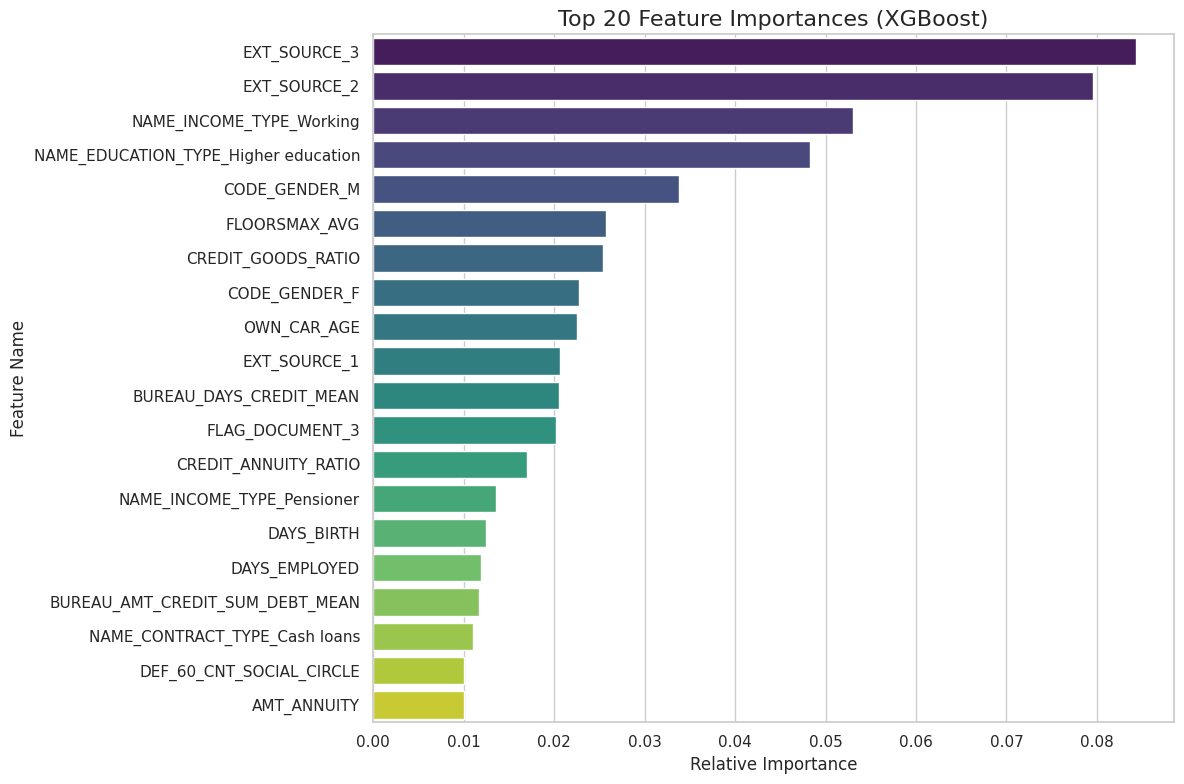

In [15]:
# 1. Extract the preprocessor and model from our best pipeline
preprocessor =  best_model.named_steps['preprocessor']
xgb_model = best_model.named_steps['classifier']

# 2. Get the feature names generated by the ColumnTransformer
feature_name = preprocessor.get_feature_names_out()

# Clean up feature names (Scikit-Learn adds 'num__' and 'cat__' prefixes)
clean_feature_names = [name.split('__')[-1] for name in feature_name]

# 3. Get the feature importances from XGBoost
importances = xgb_model.feature_importances_

# 4. Create df & sort
importance_df = pd.DataFrame({
    'Feature': clean_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(20), palette='viridis')
plt.title('Top 20 Feature Importances (XGBoost)', fontsize=16)
plt.xlabel('Relative Importance')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

## Now deployment

In [19]:
# Create 1 baseline row using median for numbers and mode for categories
baseline_row = {}
for col in x_train.columns:
    if pd.api.types.is_numeric_dtype(x_train[col]):
        baseline_row[col] = x_train[col].median()
    else:
        baseline_row[col] = x_train[col].mode()[0]

baseline_df = pd.DataFrame([baseline_row])
joblib.dump(baseline_df, 'baseline_features.joblib')
print("Done! Now download both .joblib files from Kaggle's right sidebar -> Output.")

Done! Now download both .joblib files from Kaggle's right sidebar -> Output.
